**EXPLORATORY DATA ANALYSIS (EDA)**

**Import the required libraries**

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

**Upload and load the CSV datasets**

In [8]:

from google.colab import files
import pandas as pd
import io

print("Please upload all 11 prepared CSV datasets.")

uploaded = files.upload()

# Load all uploaded CSV files
datasets = {}

for filename, content in uploaded.items():
    if filename.lower().endswith('.csv'):
        df = pd.read_csv(io.BytesIO(content))
        datasets[filename] = df
        print(f"Successfully loaded: {filename}")

print("\nAll uploaded CSV files have been loaded.")


Please upload all 11 prepared CSV datasets.


Saving annual_master_dataset.csv to annual_master_dataset (1).csv
Saving cleaning_log.csv to cleaning_log (1).csv
Saving common_period_dataset.csv to common_period_dataset (1).csv
Saving philippine_industrial_withdrawal_clean.csv to philippine_industrial_withdrawal_clean (1).csv
Saving physical_water_supply_clean.csv to physical_water_supply_clean (1).csv
Saving physical_water_use_clean.csv to physical_water_use_clean (1).csv
Saving supply_total_annual.csv to supply_total_annual (1).csv
Saving transformation_log.csv to transformation_log (1).csv
Saving use_total_annual.csv to use_total_annual (1).csv
Saving water_stress_clean.csv to water_stress_clean (1).csv
Saving water_use_efficiency_clean.csv to water_use_efficiency_clean (1).csv
Successfully loaded: annual_master_dataset (1).csv
Successfully loaded: cleaning_log (1).csv
Successfully loaded: common_period_dataset (1).csv
Successfully loaded: philippine_industrial_withdrawal_clean (1).csv
Successfully loaded: physical_water_supply_c

**Assign the datasets and verify them**

In [9]:
import os
import re

# Normalize uploaded filenames by removing numbered suffixes such as (1).
normalized_datasets = {}
for filename, df in datasets.items():
    name = os.path.splitext(filename)[0].lower().strip()
    name = re.sub(r" \(\d+\)$", "", name)
    if name in normalized_datasets:
        raise ValueError(
            f"More than one uploaded file matches '{name}'. "
            "Please upload only one copy of each prepared CSV."
        )
    normalized_datasets[name] = df

# Required datasets for the EDA activities.
required_files = [
    'physical_water_supply_clean',
    'physical_water_use_clean',
    'philippine_industrial_withdrawal_clean',
    'water_use_efficiency_clean',
    'water_stress_clean',
    'annual_master_dataset',
    'common_period_dataset',
    'supply_total_annual',
    'use_total_annual'
]

missing_files = [name for name in required_files if name not in normalized_datasets]
if missing_files:
    raise FileNotFoundError(
        'The following required CSV files were not uploaded: ' + ', '.join(missing_files)
    )

# Assign the main EDA datasets.
supply = normalized_datasets['physical_water_supply_clean']
use = normalized_datasets['physical_water_use_clean']
industrial = normalized_datasets['philippine_industrial_withdrawal_clean']
wue = normalized_datasets['water_use_efficiency_clean']
stress = normalized_datasets['water_stress_clean']
master = normalized_datasets['annual_master_dataset']
common = normalized_datasets['common_period_dataset']
supply_total_annual = normalized_datasets['supply_total_annual']
use_total_annual = normalized_datasets['use_total_annual']

# Organize and verify the seven primary datasets.
dataset_list = {
    'Water Supply': supply,
    'Water Use': use,
    'Industrial Withdrawal': industrial,
    'Water Use Efficiency': wue,
    'Water Stress': stress,
    'Annual Master': master,
    'Common Period': common
}

for name, df in dataset_list.items():
    print(f"\n===== {name} =====")
    print('Shape:', df.shape)
    print('Columns:', df.columns.tolist())
    display(df.head())

print('\nSUCCESS: All required EDA datasets are loaded and verified.')


===== Water Supply =====
Shape: (224, 13)
Columns: ['year', 'inputs', 'agriculture_forestry_and_fishing', 'mining_and_quarrying_manufacturing_and_construction', 'electricity_gas_steam_and_airconditioning_supply', 'water_supply', 'other_industries', 'total_industry', 'households', 'accumulation', 'flows_from_the_environment', 'total_supply', 'input_label']


,year,inputs,agriculture_forestry_and_fishing,mining_and_quarrying_manufacturing_and_construction,electricity_gas_steam_and_airconditioning_supply,water_supply,other_industries,total_industry,households,accumulation,flows_from_the_environment,total_supply,input_label
0,2010,..Surface water,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,190465.0,190465,SURFACE WATER
1,2010,..Ground water,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3618.0,3618,GROUND WATER
2,2010,TOTAL SUPPLY ABSTRACTED WATER,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,194083.0,194083,TOTAL SUPPLY ABSTRACTED WATER
3,2010,..For distribution,NaN,NaN,NaN,1242.0,NaN,1242.0,NaN,NaN,NaN,1242,FOR DISTRIBUTION
4,2010,..For own-use,67882.0,8267.0,110808.0,724.0,4483.0,192165.0,NaN,NaN,NaN,192165,FOR OWN-USE



===== Water Use =====
Shape: (208, 13)
Columns: ['year', 'inputs', 'agriculture_forestry_and_fishing', 'mining_and_quarrying_manufacturing_and_construction', 'electricity_gas_steam_and_airconditioning_supply', 'water_supply', 'other_industries', 'total_industry', 'households', 'accumulation', 'flows_to_the_environment', 'total_use', 'input_label']


,year,inputs,agriculture_forestry_and_fishing,mining_and_quarrying_manufacturing_and_construction,electricity_gas_steam_and_airconditioning_supply,water_supply,other_industries,total_industry,households,accumulation,flows_to_the_environment,total_use,input_label
0,2010,..Surface water,66862.0,7850.0,110747.0,1829.0,3176.0,190465.0,NaN,NaN,NaN,190465,SURFACE WATER
1,2010,..Ground water,1020.0,417.0,61.0,813.0,1307.0,3618.0,NaN,NaN,NaN,3618,GROUND WATER
2,2010,TOTAL USE ABSTRACTED WATER,67882.0,8267.0,110808.0,2643.0,4483.0,194083.0,NaN,NaN,NaN,194083,TOTAL USE ABSTRACTED WATER
3,2010,..Distributed water,71.0,342.0,13.0,0.0,423.0,848.0,394.0,NaN,NaN,1242,DISTRIBUTED WATER
4,2010,..Own use of water,67882.0,8267.0,110808.0,2.0,4483.0,191442.0,722.0,NaN,NaN,192165,OWN USE OF WATER



===== Industrial Withdrawal =====
Shape: (29, 5)
Columns: ['entity', 'code', 'year', 'industrial_water_withdrawal', 'withdrawal_mcm']


,entity,code,year,industrial_water_withdrawal,withdrawal_mcm
0,Philippines,PHL,1995,2296000004,2296.000004
1,Philippines,PHL,1996,2418200016,2418.200016
2,Philippines,PHL,1997,2540400028,2540.400028
3,Philippines,PHL,1998,2662600040,2662.600040
4,Philippines,PHL,1999,2784800053,2784.800053


... (5 outputs left out)

,year,total_supply,total_use,owid_industrial_withdrawal_mcm,water_used_industry,wue_industry,wue_overall,water_withdrawal_mcm,water_stress
0,1995,NaN,NaN,2296.000004,NaN,NaN,NaN,NaN,NaN
1,1996,NaN,NaN,2418.200016,NaN,NaN,NaN,NaN,NaN
2,1997,NaN,NaN,2540.400028,NaN,NaN,NaN,NaN,NaN
3,1998,NaN,NaN,2662.600040,NaN,NaN,NaN,NaN,NaN
4,1999,NaN,NaN,2784.800053,NaN,NaN,NaN,NaN,NaN



===== Common Period =====
Shape: (8, 9)
Columns: ['year', 'total_supply', 'total_use', 'owid_industrial_withdrawal_mcm', 'water_used_industry', 'wue_industry', 'wue_overall', 'water_withdrawal_mcm', 'water_stress']


,year,total_supply,total_use,owid_industrial_withdrawal_mcm,water_used_industry,wue_industry,wue_overall,water_withdrawal_mcm,water_stress
0,2016,603807.0,603807.0,10560.000420,10629.940687,449.321980,177.983628,86298.737394,0.263830
1,2017,635746.0,635746.0,15915.530205,15915.530000,321.398345,178.927187,91920.201844,0.281016
2,2018,643195.0,643195.0,16188.804626,16188.805031,339.160116,190.082450,92282.286983,0.282123
3,2019,650108.0,650108.0,9880.982399,9880.981984,586.111584,217.084637,85994.513979,0.262900
4,2020,654859.0,654859.0,10633.614540,10633.614978,471.651081,192.235375,87477.269175,0.267433



SUCCESS: All required EDA datasets are loaded and verified.


**1. National Water Supply Analysis**

In [10]:
supply_total_annual = normalized_datasets['supply_total_annual']

In [11]:
print(supply_total_annual.describe())

              year   total_supply
count    16.000000      16.000000
mean   2017.500000  636062.937500
std       4.760952   45103.751681
min    2010.000000  581572.000000
25%    2013.750000  598404.250000
50%    2017.500000  639470.500000
75%    2021.250000  666538.000000
max    2025.000000  739393.000000


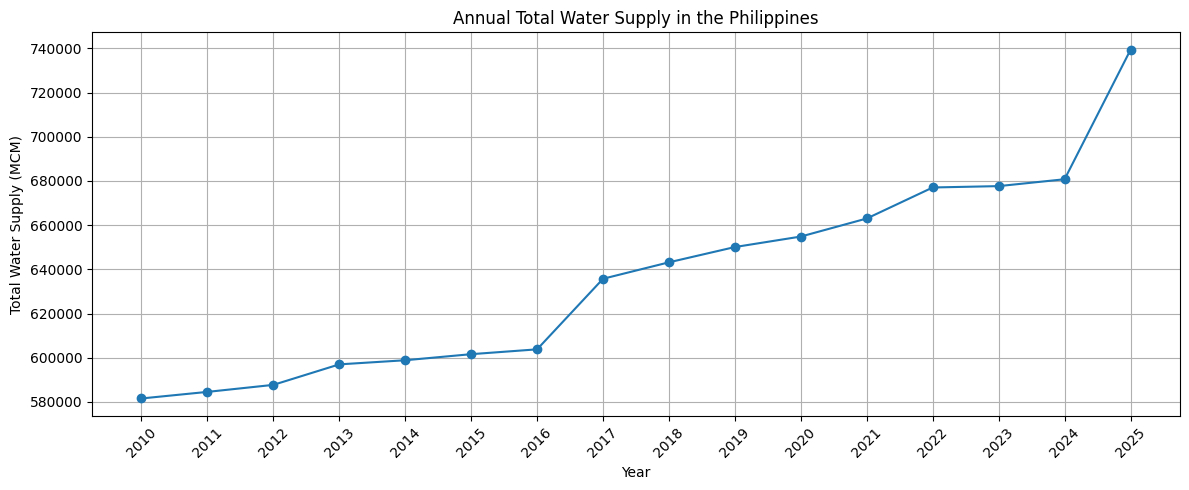

In [12]:
plt.figure(figsize=(12, 5))

plt.plot(
    supply_total_annual['year'],
    supply_total_annual['total_supply'],
    marker='o'
)

plt.title('Annual Total Water Supply in the Philippines')
plt.xlabel('Year')
plt.ylabel('Total Water Supply (MCM)')
plt.grid(True)
plt.xticks(supply_total_annual['year'], rotation=45)
plt.tight_layout()
plt.show()

In [13]:
highest = supply_total_annual.loc[
    supply_total_annual['total_supply'].idxmax()
]

lowest = supply_total_annual.loc[
    supply_total_annual['total_supply'].idxmin()
]

print("Highest Water Supply:")
display(highest)

print("Lowest Water Supply:")
display(lowest)

Highest Water Supply:


,15
year,2025
total_supply,739393


Lowest Water Supply:


,0
year,2010
total_supply,581572


ANALYSIS:

**1. Does the total water supply generally increase or decrease?**

The total water supply in the Philippines generally increased from 2010 to 2025.

**2. Which year recorded the highest supply?**

The highest total water supply was recorded in 2025, with 739,393 MCM.

**3. Which year recorded the lowest supply?**

The lowest total water supply was recorded in 2010, with 581,572 MCM.

**4. Are there noticeable fluctuations?**

Yes. Although the overall trend is increasing, there are noticeable changes between years. The largest increases occurred in 2017 and 2025, while a smaller increase was observed in 2022.

**5. What might these patterns indicate about Philippine water supply?**

The results indicate that the recorded total water supply generally increased over the 16-year period. However, the changes were not consistent every year, suggesting that the country's recorded water supply varied over time.

**2. National Water Use Analysis**

In [14]:
use_total_annual = normalized_datasets['use_total_annual']

print("Dataset shape:", use_total_annual.shape)
print("Columns:", use_total_annual.columns.tolist())
display(use_total_annual.head())

Dataset shape: (16, 2)
Columns: ['year', 'total_use']


,year,total_use
0,2010,581572
1,2011,584547
2,2012,587724
3,2013,597004
4,2014,598871


In [15]:
print(use_total_annual.describe())

              year      total_use
count    16.000000      16.000000
mean   2017.500000  636062.937500
std       4.760952   45103.751681
min    2010.000000  581572.000000
25%    2013.750000  598404.250000
50%    2017.500000  639470.500000
75%    2021.250000  666538.000000
max    2025.000000  739393.000000


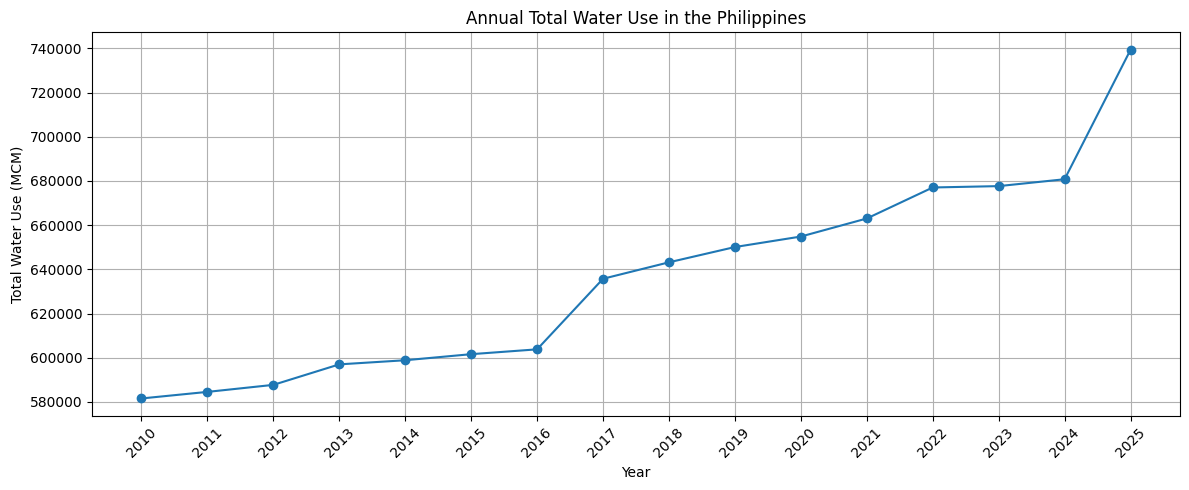

In [16]:
plt.figure(figsize=(12, 5))

plt.plot(
    use_total_annual['year'],
    use_total_annual['total_use'],
    marker='o'
)

plt.title('Annual Total Water Use in the Philippines')
plt.xlabel('Year')
plt.ylabel('Total Water Use (MCM)')
plt.grid(True)
plt.xticks(use_total_annual['year'], rotation=45)
plt.tight_layout()
plt.show()

In [17]:
highest = use_total_annual.loc[
    use_total_annual['total_use'].idxmax()
]

lowest = use_total_annual.loc[
    use_total_annual['total_use'].idxmin()
]

print("Highest Water Use:")
display(highest)

print("Lowest Water Use:")
display(lowest)

Highest Water Use:


,15
year,2025
total_use,739393


Lowest Water Use:


,0
year,2010
total_use,581572


**ANALYSIS**

**1. Does national water use generally increase or decrease?**

National water use generally increased from 2010 to 2025.

**2. Which year recorded the highest water use?**

The highest total water use was recorded in 2025, with 739,393 MCM.

**3. Which year recorded the lowest water use?**

The lowest total water use was recorded in 2010, with 581,572 MCM.

**4. Are there noticeable fluctuations?**

Yes. The largest increases occurred in 2017 and 2025, while another noticeable increase occurred in 2022. However, there were also years when the increase was relatively small.

**5. What might the observed changes suggest about national water utilization?**

The results indicate that the recorded total water use generally increased throughout the observed period. This shows changes in the country's recorded water utilization over time.

**Note:** The prepared annual total water supply and total water use datasets contain exactly the same values for every year from 2010 to 2025. Therefore, these results should not be interpreted as independent evidence that water supply and water use are equal. The original PSA accounting definitions and the preparation process should be reviewed.

**3. Sectoral Water Utilization Analysis**

In [18]:
print("Dataset shape:", use.shape)
print("Columns:", use.columns.tolist())
display(use.head())

Dataset shape: (208, 13)
Columns: ['year', 'inputs', 'agriculture_forestry_and_fishing', 'mining_and_quarrying_manufacturing_and_construction', 'electricity_gas_steam_and_airconditioning_supply', 'water_supply', 'other_industries', 'total_industry', 'households', 'accumulation', 'flows_to_the_environment', 'total_use', 'input_label']


,year,inputs,agriculture_forestry_and_fishing,mining_and_quarrying_manufacturing_and_construction,electricity_gas_steam_and_airconditioning_supply,water_supply,other_industries,total_industry,households,accumulation,flows_to_the_environment,total_use,input_label
0,2010,..Surface water,66862.0,7850.0,110747.0,1829.0,3176.0,190465.0,NaN,NaN,NaN,190465,SURFACE WATER
1,2010,..Ground water,1020.0,417.0,61.0,813.0,1307.0,3618.0,NaN,NaN,NaN,3618,GROUND WATER
2,2010,TOTAL USE ABSTRACTED WATER,67882.0,8267.0,110808.0,2643.0,4483.0,194083.0,NaN,NaN,NaN,194083,TOTAL USE ABSTRACTED WATER
3,2010,..Distributed water,71.0,342.0,13.0,0.0,423.0,848.0,394.0,NaN,NaN,1242,DISTRIBUTED WATER
4,2010,..Own use of water,67882.0,8267.0,110808.0,2.0,4483.0,191442.0,722.0,NaN,NaN,192165,OWN USE OF WATER


In [19]:
print(use['input_label'].dropna().unique())

['SURFACE WATER' 'GROUND WATER' 'TOTAL USE ABSTRACTED WATER'
 'DISTRIBUTED WATER' 'OWN USE OF WATER' 'RETURN TO INLAND WATER RESOURCES'
 'RETURN TO OTHER SOURCES' 'TOTAL RETURN FLOWS'
 'EVAPORATION OF ABSTRACTED WATER' 'TRANSPIRATION'
 'WATER INCORPORATED TO PRODUCTS'
 'TOTAL WATER EVAPORATED, TRANSPIRED AND INCORPORATED INTO PRODUCTS'
 'TOTAL USE']


In [20]:
sector_use = use[
    use['input_label'].astype(str).str.strip().str.upper()
    == 'TOTAL USE ABSTRACTED WATER'
].copy()

display(sector_use.head())
print("Selected records:", len(sector_use))

,year,inputs,agriculture_forestry_and_fishing,mining_and_quarrying_manufacturing_and_construction,electricity_gas_steam_and_airconditioning_supply,water_supply,other_industries,total_industry,households,accumulation,flows_to_the_environment,total_use,input_label
2,2010,TOTAL USE ABSTRACTED WATER,67882.0,8267.0,110808.0,2643.0,4483.0,194083.0,NaN,NaN,NaN,194083,TOTAL USE ABSTRACTED WATER
15,2011,TOTAL USE ABSTRACTED WATER,67885.0,8959.0,111024.0,2728.0,4472.0,195068.0,NaN,NaN,NaN,195068,TOTAL USE ABSTRACTED WATER
28,2012,TOTAL USE ABSTRACTED WATER,67892.0,9037.0,111899.0,2889.0,4412.0,196129.0,NaN,NaN,NaN,196129,TOTAL USE ABSTRACTED WATER
41,2013,TOTAL USE ABSTRACTED WATER,67891.0,9054.0,114800.0,2997.0,4476.0,199219.0,NaN,NaN,NaN,199219,TOTAL USE ABSTRACTED WATER
54,2014,TOTAL USE ABSTRACTED WATER,67911.0,9088.0,115275.0,3153.0,4412.0,199840.0,NaN,NaN,NaN,199840,TOTAL USE ABSTRACTED WATER


Selected records: 16


In [21]:
print(sector_use.columns.tolist())

['year', 'inputs', 'agriculture_forestry_and_fishing', 'mining_and_quarrying_manufacturing_and_construction', 'electricity_gas_steam_and_airconditioning_supply', 'water_supply', 'other_industries', 'total_industry', 'households', 'accumulation', 'flows_to_the_environment', 'total_use', 'input_label']


Available sectors: ['agriculture_forestry_and_fishing', 'mining_and_quarrying_manufacturing_and_construction', 'electricity_gas_steam_and_airconditioning_supply', 'water_supply', 'other_industries']


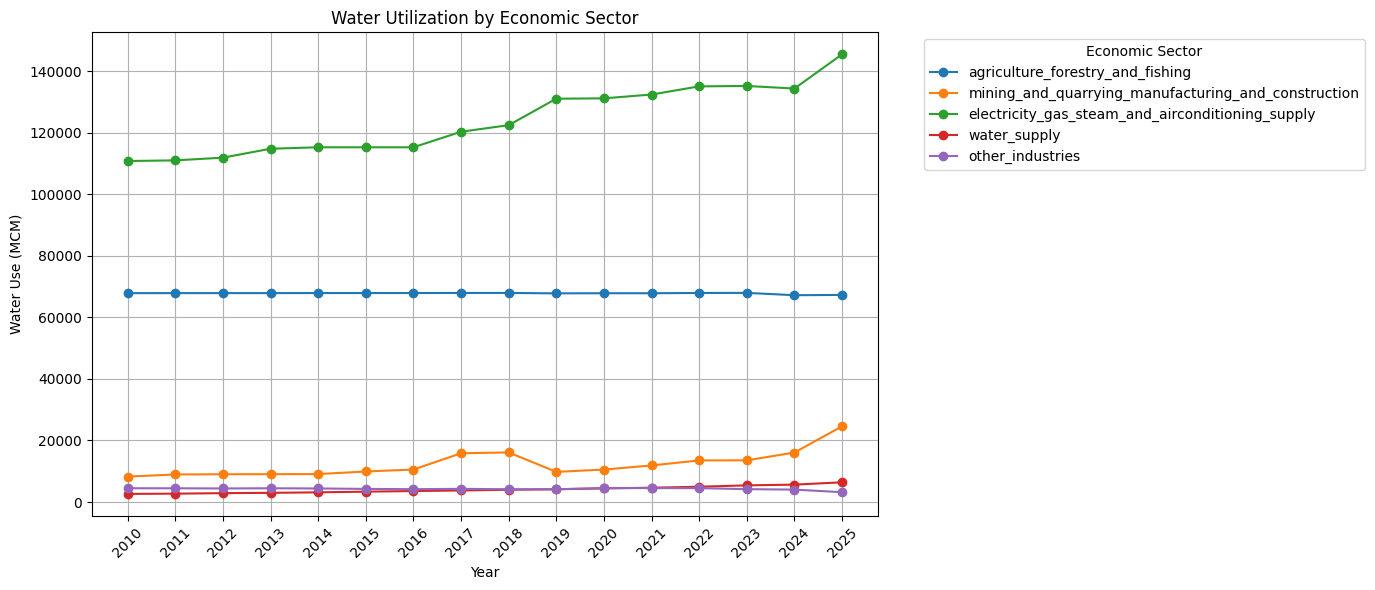

Average Water Utilization by Sector (MCM):


,average_water_use_mcm
electricity_gas_steam_and_airconditioning_supply,123869.3125
agriculture_forestry_and_fishing,67818.5625
mining_and_quarrying_manufacturing_and_construction,12306.9375
other_industries,4271.5625
water_supply,4053.0000


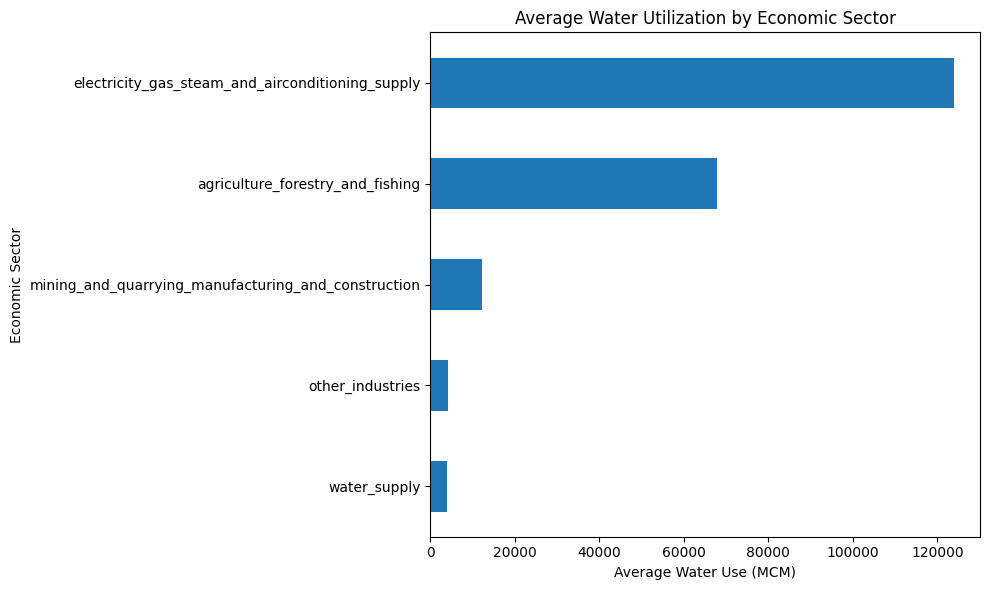

Missing values per sector:


,missing_count
agriculture_forestry_and_fishing,0
mining_and_quarrying_manufacturing_and_construction,0
electricity_gas_steam_and_airconditioning_supply,0
water_supply,0
other_industries,0
households,16


In [22]:
# Identify the sector columns available in the selected accounting category.
sector_columns = [
    'agriculture_forestry_and_fishing',
    'mining_and_quarrying_manufacturing_and_construction',
    'electricity_gas_steam_and_airconditioning_supply',
    'water_supply',
    'other_industries',
    'households'
]

# Keep only columns that exist and contain at least one numerical observation.
available_sectors = [
    col for col in sector_columns
    if col in sector_use.columns and pd.to_numeric(sector_use[col], errors='coerce').notna().any()
]

if not available_sectors:
    raise ValueError('No sector columns with numerical observations were found.')

print('Available sectors:', available_sectors)

# Plot sectoral water utilization over time.
sector_use = sector_use.sort_values('year')
sector_use.plot(
    x='year',
    y=available_sectors,
    figsize=(14, 6),
    marker='o'
)
plt.title('Water Utilization by Economic Sector')
plt.xlabel('Year')
plt.ylabel('Water Use (MCM)')
plt.grid(True)
plt.xticks(sector_use['year'], rotation=45)
plt.legend(title='Economic Sector', bbox_to_anchor=(1.05, 1))
plt.tight_layout()
plt.show()

# Calculate and plot average utilization for sectors with available values.
sector_averages = sector_use[available_sectors].mean().sort_values(ascending=False)
print('Average Water Utilization by Sector (MCM):')
display(sector_averages.to_frame(name='average_water_use_mcm'))

sector_averages.sort_values().plot(kind='barh', figsize=(10, 6))
plt.title('Average Water Utilization by Economic Sector')
plt.xlabel('Average Water Use (MCM)')
plt.ylabel('Economic Sector')
plt.tight_layout()
plt.show()

# Report missing values separately; missing values are not treated as zero.
print('Missing values per sector:')
display(sector_use[sector_columns].isna().sum().to_frame(name='missing_count'))

**ANALYSIS**

**1. Which economic sector has the highest average water utilization?**

The Electricity, Gas, Steam, and Airconditioning Supply sector has the highest average water utilization, with approximately 123,869.31 MCM.

**2. Which sector has the lowest average water utilization?**

The Water Supply sector has the lowest average among the sectors with available numerical values, with an average of 4,053.00 MCM. Household values were unavailable in the selected accounting category because all 16 observations were missing.

**3. Which sectors show noticeable increases or decreases?**

Electricity, Gas, Steam, and Airconditioning Supply generally increased from 110,808 MCM in 2010 to 145,483 MCM in 2025. The Mining, Quarrying, Manufacturing, and Construction category also fluctuated and recorded a noticeable increase to 24,613 MCM in 2025. Agriculture, Forestry and Fishing remained relatively stable, while Water Supply generally increased over the observed period.

**4. Do any sectors appear to follow similar trends?**

The sectors do not all follow the same pattern. Agriculture, Forestry and Fishing remained relatively stable. Electricity, Gas, Steam, and Airconditioning Supply and Water Supply generally increased. Mining, Quarrying, Manufacturing, and Construction showed larger fluctuations, while Other Industries varied and decreased in the final year.

**5. What do the results suggest about sectoral water utilization in the Philippines?**

The results show that water utilization differs considerably among the economic sectors. Electricity, Gas, Steam, and Airconditioning Supply recorded the highest average among the sectors with available values, followed by Agriculture, Forestry and Fishing. Household utilization could not be compared because its values were missing in the selected accounting category. The combined Mining, Quarrying, Manufacturing, and Construction category also cannot be used to identify mining's individual water utilization.

**4. Industrial Water Withdrawal Analysis**

In [23]:
print("Dataset shape:", industrial.shape)
print("Columns:", industrial.columns.tolist())
display(industrial.head())

Dataset shape: (29, 5)
Columns: ['entity', 'code', 'year', 'industrial_water_withdrawal', 'withdrawal_mcm']


,entity,code,year,industrial_water_withdrawal,withdrawal_mcm
0,Philippines,PHL,1995,2296000004,2296.000004
1,Philippines,PHL,1996,2418200016,2418.200016
2,Philippines,PHL,1997,2540400028,2540.400028
3,Philippines,PHL,1998,2662600040,2662.600040
4,Philippines,PHL,1999,2784800053,2784.800053


In [24]:
print(industrial['withdrawal_mcm'].describe())

count       29.000000
mean      7912.381230
std       4029.522137
min       2296.000004
25%       4423.999786
50%       8253.999710
75%       9930.999756
max      16188.804626
Name: withdrawal_mcm, dtype: float64


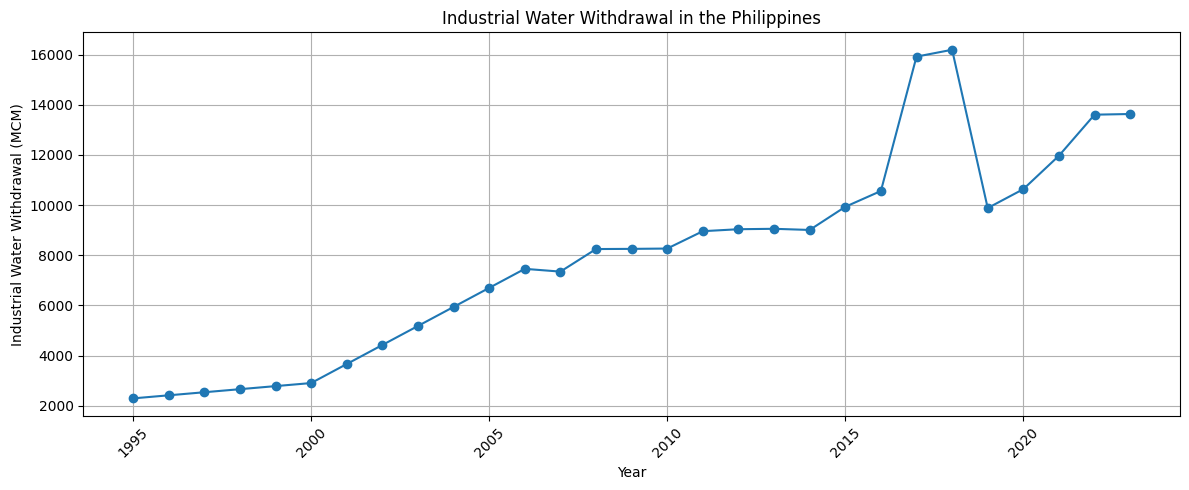

In [25]:
industrial = industrial.sort_values('year')

plt.figure(figsize=(12, 5))

plt.plot(
    industrial['year'],
    industrial['withdrawal_mcm'],
    marker='o'
)

plt.title('Industrial Water Withdrawal in the Philippines')
plt.xlabel('Year')
plt.ylabel('Industrial Water Withdrawal (MCM)')
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [26]:
highest = industrial.loc[
    industrial['withdrawal_mcm'].idxmax()
]

lowest = industrial.loc[
    industrial['withdrawal_mcm'].idxmin()
]

print("Highest Industrial Water Withdrawal:")
display(highest)

print("Lowest Industrial Water Withdrawal:")
display(lowest)

Highest Industrial Water Withdrawal:


,23
entity,Philippines
code,PHL
year,2018
industrial_water_withdrawal,16188804626
withdrawal_mcm,16188.804626


Lowest Industrial Water Withdrawal:


,0
entity,Philippines
code,PHL
year,1995
industrial_water_withdrawal,2296000004
withdrawal_mcm,2296.000004


**ANALYSIS**

**1. Does industrial water withdrawal generally increase or decrease?**

Industrial water withdrawal generally increased over the observed period from 1995 to 2023, although there were noticeable fluctuations.

**2. Which year recorded the highest withdrawal?**

The highest industrial water withdrawal was recorded in 2018, with approximately 16,188.80 MCM.

**3. Which year recorded the lowest withdrawal?**

The lowest industrial water withdrawal was recorded in 1995, with approximately 2,296.00 MCM.

**4. Are there noticeable changes between years?**

Yes. Industrial water withdrawal increased gradually during the earlier years, followed by a significant increase in 2017 and 2018. It then decreased considerably in 2019 before increasing again from 2020 to 2023.

**5. What might these trends indicate about industrial water demand?**

The results indicate that industrial water withdrawal generally increased over the long term. However, the fluctuations suggest that industrial water demand did not increase at a constant rate throughout the observed period. These changes highlight the importance of monitoring industrial water withdrawal over time.

**5. Industrial Water-Use Efficiency Analysis**

In [27]:
print("Dataset shape:", wue.shape)
print("Columns:", wue.columns.tolist())
display(wue.head())

Dataset shape: (10, 12)
Columns: ['year', 'gva_agriculture', 'gva_industry', 'gva_services', 'water_used_agriculture', 'water_used_industry', 'water_used_services', 'wue_agriculture', 'wue_industry', 'wue_services', 'wue_overall', 'change_in_wue']


,year,gva_agriculture,gva_industry,gva_services,water_used_agriculture,water_used_industry,water_used_services,wue_agriculture,wue_industry,wue_services,wue_overall,change_in_wue
0,2016,9.691714e+05,4776266,9614325,67916.478579,10629.940687,7752.318127,14.270048,449.321980,1256.645108,177.983628,0.067436
1,2017,1.014180e+06,5115225,10317618,67942.361844,15915.530000,8062.310000,14.927067,321.398345,1330.907456,178.927187,0.005301
2,2018,1.038671e+06,5490597,11011975,67944.549454,16188.805031,8148.932498,15.287042,339.160116,1365.858544,190.082450,0.062345
3,2019,1.069192e+06,5791358,11807538,67809.224838,9880.981984,8304.307156,15.767645,586.111584,1421.857089,217.084637,0.142055
4,2020,1.058773e+06,5015356,10742097,67851.090050,10633.614978,8992.564147,15.604357,471.651081,1194.553280,192.235375,-0.114468


In [28]:
display(wue[['year', 'wue_industry']])

,year,wue_industry
0,2016,449.321980
1,2017,321.398345
2,2018,339.160116
3,2019,586.111584
4,2020,471.651081
5,2021,455.464721
6,2022,426.779041
7,2023,441.188355
8,2024,392.855686
9,2025,261.465112


In [29]:
efficiency_columns = [
    'wue_agriculture',
    'wue_industry',
    'wue_services'
]

available_efficiency = [
    col for col in efficiency_columns
    if col in wue.columns
]

display(wue[available_efficiency].describe())

,wue_agriculture,wue_industry,wue_services
count,10.000000,10.000000,10.000000
mean,15.490156,414.539602,1348.702258
std,0.597580,91.105956,109.607140
min,14.270048,261.465112,1194.553280
25%,15.304734,352.584009,1267.737653
50%,15.542685,433.983698,1348.383000
75%,15.799502,453.929036,1410.493101
max,16.475880,586.111584,1553.613654


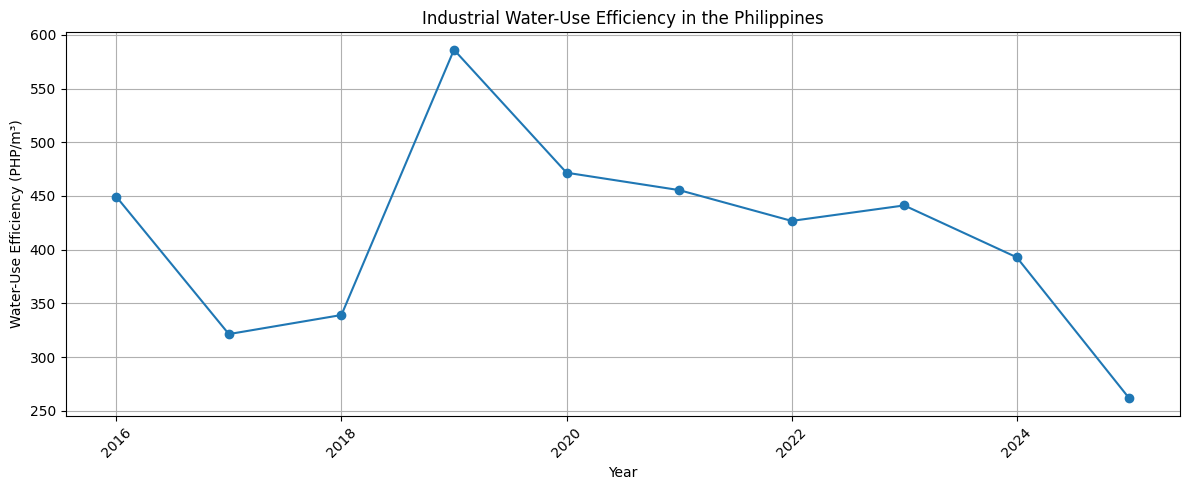

In [30]:
wue = wue.sort_values('year')

plt.figure(figsize=(12, 5))

plt.plot(
    wue['year'],
    wue['wue_industry'],
    marker='o'
)

plt.title('Industrial Water-Use Efficiency in the Philippines')
plt.xlabel('Year')
plt.ylabel('Water-Use Efficiency (PHP/m³)')
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

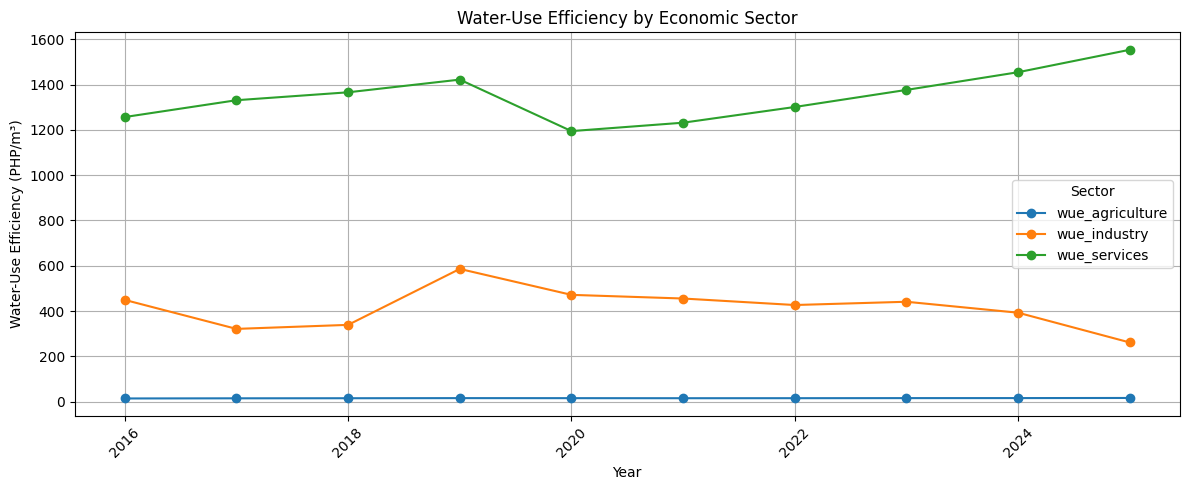

In [31]:
wue.plot(
    x='year',
    y=available_efficiency,
    figsize=(12, 5),
    marker='o'
)

plt.title('Water-Use Efficiency by Economic Sector')
plt.xlabel('Year')
plt.ylabel('Water-Use Efficiency (PHP/m³)')
plt.grid(True)
plt.xticks(rotation=45)
plt.legend(title='Sector')
plt.tight_layout()
plt.show()

**ANALYSIS**

**1. Does industrial water-use efficiency increase or decrease?**

Industrial water-use efficiency fluctuated throughout 2016–2025. It decreased from 2016 to 2017, increased to its highest value in 2019, and then generally declined, reaching its lowest value in 2025.

**2. Which year has the highest industrial efficiency?**

The highest industrial water-use efficiency was recorded in 2019, at approximately 586.11 PHP/m³.

**3. Which year has the lowest industrial efficiency?**

The lowest industrial water-use efficiency was recorded in 2025, at approximately 261.47 PHP/m³.

**4. How does industrial efficiency compare with agriculture and services?**

The Services sector recorded the highest water-use efficiency in every year from 2016 to 2025, followed by Industry. Agriculture recorded the lowest efficiency throughout the period.

**5. What might the results suggest about economic output relative to water used?**

The results indicate differences in the economic value generated per cubic meter of water used across the sectors. The decline in industrial water-use efficiency after 2019, particularly by 2025, means that the recorded economic value generated per cubic meter of industrial water used was lower than at its 2019 peak. This does not by itself prove that physical water consumption increased; it shows a change in the measured output-to-water-use ratio.

**6. National Water Stress Analysis**

In [32]:
print("Dataset shape:", stress.shape)
print("Columns:", stress.columns.tolist())
display(stress.head())

Dataset shape: (10, 5)
Columns: ['year', 'water_withdrawal_mcm', 'water_withdrawal_bcm', 'water_stress', 'water_stress_percentage']


,year,water_withdrawal_mcm,water_withdrawal_bcm,water_stress,water_stress_percentage
0,2016,86298.737394,86.298737,0.263830,26.382983
1,2017,91920.201844,91.920202,0.281016,28.101560
2,2018,92282.286983,92.282287,0.282123,28.212255
3,2019,85994.513979,85.994514,0.262900,26.289977
4,2020,87477.269175,87.477269,0.267433,26.743280


In [33]:
display(stress[['year', 'water_stress']])

,year,water_stress
0,2016,0.263830
1,2017,0.281016
2,2018,0.282123
3,2019,0.262900
4,2020,0.267433
5,2021,0.272089
6,2022,0.278315
7,2023,0.278828
8,2024,0.284575
9,2025,0.310642


In [34]:
stress['water_stress_percentage'] = (
    stress['water_stress'] * 100
)

display(
    stress[['year', 'water_stress', 'water_stress_percentage']]
)

,year,water_stress,water_stress_percentage
0,2016,0.263830,26.382983
1,2017,0.281016,28.101560
2,2018,0.282123,28.212255
3,2019,0.262900,26.289977
4,2020,0.267433,26.743280
5,2021,0.272089,27.208916
6,2022,0.278315,27.831516
7,2023,0.278828,27.882785
8,2024,0.284575,28.457509
9,2025,0.310642,31.064179


In [35]:
print(stress['water_stress_percentage'].describe())

count    10.000000
mean     27.817496
std       1.378687
min      26.289977
25%      26.859689
50%      27.857150
75%      28.184581
max      31.064179
Name: water_stress_percentage, dtype: float64


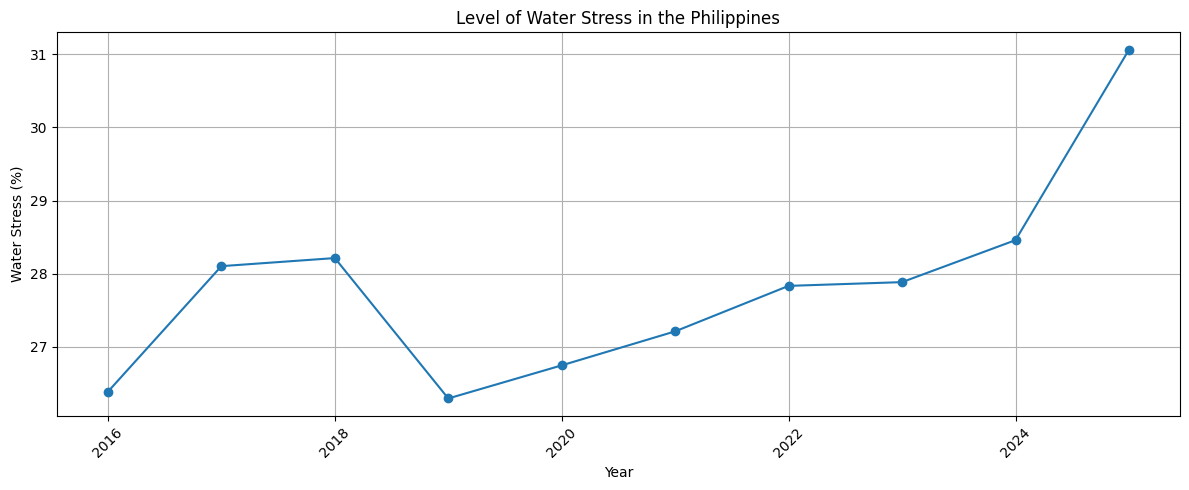

In [36]:
stress = stress.sort_values('year')

plt.figure(figsize=(12, 5))

plt.plot(
    stress['year'],
    stress['water_stress_percentage'],
    marker='o'
)

plt.title('Level of Water Stress in the Philippines')
plt.xlabel('Year')
plt.ylabel('Water Stress (%)')
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [37]:
highest = stress.loc[
    stress['water_stress_percentage'].idxmax()
]

lowest = stress.loc[
    stress['water_stress_percentage'].idxmin()
]

print("Highest Water Stress:")
display(highest)

print("Lowest Water Stress:")
display(lowest)

Highest Water Stress:


,9
year,2025.000000
water_withdrawal_mcm,101610.928844
water_withdrawal_bcm,101.610929
water_stress,0.310642
water_stress_percentage,31.064179


Lowest Water Stress:


,3
year,2019.000000
water_withdrawal_mcm,85994.513979
water_withdrawal_bcm,85.994514
water_stress,0.262900
water_stress_percentage,26.289977


**ANALYSIS**

**1. Does national water stress generally increase or decrease?**

National water stress generally increased from 2019 to 2025, although some fluctuations occurred between years.

**2. Which year recorded the highest water stress?**

The highest national water stress was recorded in 2025, at approximately 31.06%.

**3. Which year recorded the lowest water stress?**

The lowest national water stress was recorded in 2019, at approximately 26.29%.

**4. Are there noticeable changes between years?**

Yes. Water stress increased from 2016 to 2018, decreased in 2019, and then generally increased from 2020 to 2025. The most noticeable increase occurred in 2025.

**5. What might these observations suggest about pressure on available freshwater resources?**

The results indicate that the national level of water stress increased toward the end of the observed period. This suggests growing pressure on available freshwater resources at the national level. However, these results do not represent the specific water conditions of every region in the Philippines.

**7. Integrated Data Analysis**

In [38]:
print("Dataset shape:", common.shape)
print("Columns:", common.columns.tolist())

display(common.head())
print(common.describe())

Dataset shape: (8, 9)
Columns: ['year', 'total_supply', 'total_use', 'owid_industrial_withdrawal_mcm', 'water_used_industry', 'wue_industry', 'wue_overall', 'water_withdrawal_mcm', 'water_stress']


,year,total_supply,total_use,owid_industrial_withdrawal_mcm,water_used_industry,wue_industry,wue_overall,water_withdrawal_mcm,water_stress
0,2016,603807.0,603807.0,10560.000420,10629.940687,449.321980,177.983628,86298.737394,0.263830
1,2017,635746.0,635746.0,15915.530205,15915.530000,321.398345,178.927187,91920.201844,0.281016
2,2018,643195.0,643195.0,16188.804626,16188.805031,339.160116,190.082450,92282.286983,0.282123
3,2019,650108.0,650108.0,9880.982399,9880.981984,586.111584,217.084637,85994.513979,0.262900
4,2020,654859.0,654859.0,10633.614540,10633.614978,471.651081,192.235375,87477.269175,0.267433


             year   total_supply      total_use  \
count     8.00000       8.000000       8.000000   
mean   2019.50000  650686.125000  650686.125000   
std       2.44949   24117.523744   24117.523744   
min    2016.00000  603807.000000  603807.000000   
25%    2017.75000  641332.750000  641332.750000   
50%    2019.50000  652483.500000  652483.500000   
75%    2021.25000  666538.000000  666538.000000   
max    2023.00000  677680.000000  677680.000000   

       owid_industrial_withdrawal_mcm  water_used_industry  wue_industry  \
count                        8.000000             8.000000      8.000000   
mean                     12796.819568         12805.562097    436.384403   
std                       2433.363621          2424.287979     81.926015   
min                       9880.982399          9880.981984    321.398345   
25%                      10615.211010         10632.696406    404.874310   
50%                      12783.420086         12783.419809    445.255167   
75%     

In [39]:
# Select relevant indicators for the integrated correlation analysis.
# total_use is omitted because it duplicates total_supply in this prepared file.
# water_withdrawal_mcm is omitted because it is a component of the water-stress indicator.
selected_columns = [
    'total_supply',
    'owid_industrial_withdrawal_mcm',
    'water_used_industry',
    'wue_industry',
    'wue_overall',
    'water_stress'
]

missing_columns = [col for col in selected_columns if col not in common.columns]
if missing_columns:
    raise KeyError('Missing expected common-period columns: ' + ', '.join(missing_columns))

# Ensure selected variables are numeric before calculating correlations.
correlation_data = common[selected_columns].apply(pd.to_numeric, errors='coerce')
print('Common-period years:', common['year'].min(), 'to', common['year'].max())
print('Number of annual observations:', len(common))
print('Variables included:', selected_columns)

correlation = correlation_data.corr(method='pearson')
print('Pearson correlation matrix:')
display(correlation.round(3))

# Show the key relationships discussed in the interpretation.
key_pairs = [
    ('owid_industrial_withdrawal_mcm', 'water_stress'),
    ('water_used_industry', 'water_stress'),
    ('wue_industry', 'water_stress'),
    ('wue_overall', 'water_stress'),
    ('owid_industrial_withdrawal_mcm', 'water_used_industry')
]
print('Key pairwise correlations:')
for first, second in key_pairs:
    print(f'{first} vs {second}: {correlation.loc[first, second]:.3f}')

Common-period years: 2016 to 2023
Number of annual observations: 8
Variables included: ['total_supply', 'owid_industrial_withdrawal_mcm', 'water_used_industry', 'wue_industry', 'wue_overall', 'water_stress']
Pearson correlation matrix:


,total_supply,owid_industrial_withdrawal_mcm,water_used_industry,wue_industry,wue_overall,water_stress
total_supply,1.000,0.143,0.136,0.145,0.800,0.387
owid_industrial_withdrawal_mcm,0.143,1.000,1.000,-0.896,-0.192,0.961
water_used_industry,0.136,1.000,1.000,-0.898,-0.198,0.960
wue_industry,0.145,-0.896,-0.898,1.000,0.555,-0.821
wue_overall,0.800,-0.192,-0.198,0.555,1.000,0.008
water_stress,0.387,0.961,0.960,-0.821,0.008,1.000


Key pairwise correlations:
owid_industrial_withdrawal_mcm vs water_stress: 0.961
water_used_industry vs water_stress: 0.960
wue_industry vs water_stress: -0.821
wue_overall vs water_stress: 0.008
owid_industrial_withdrawal_mcm vs water_used_industry: 1.000


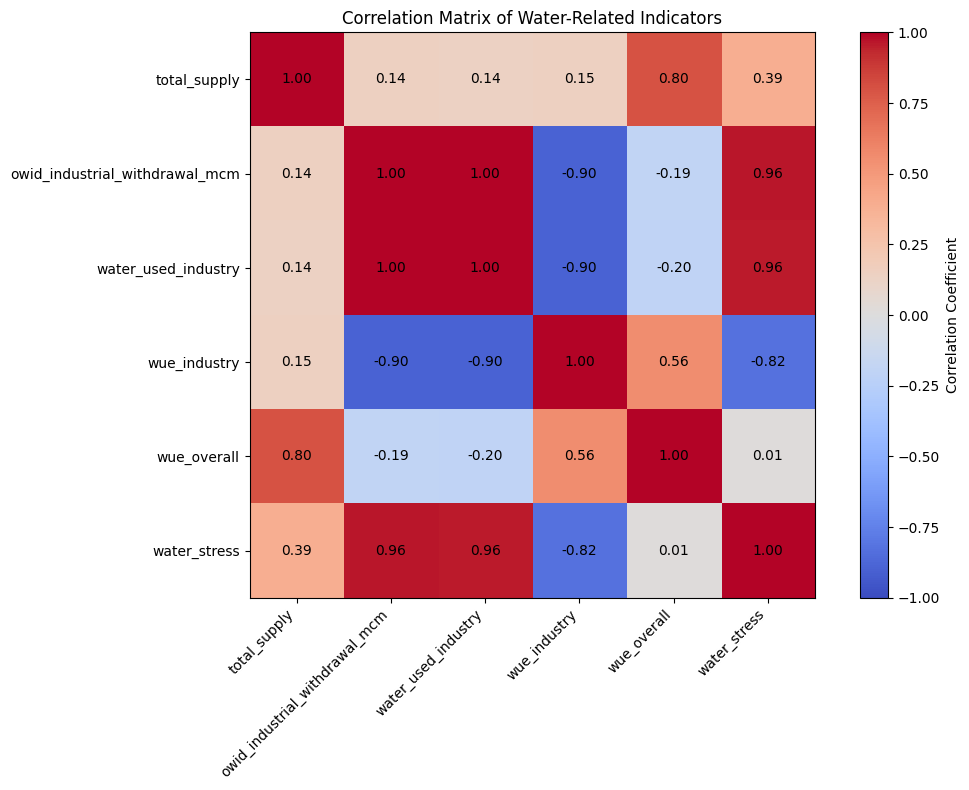

In [40]:

plt.figure(figsize=(11, 8))

plt.imshow(
    correlation,
    cmap='coolwarm',
    interpolation='nearest',
    vmin=-1,
    vmax=1
)

plt.colorbar(label='Correlation Coefficient')

plt.xticks(
    range(len(correlation.columns)),
    correlation.columns,
    rotation=45,
    ha='right'
)

plt.yticks(
    range(len(correlation.columns)),
    correlation.columns
)

plt.title('Correlation Matrix of Water-Related Indicators')

for i in range(len(correlation.columns)):
    for j in range(len(correlation.columns)):
        plt.text(
            j,
            i,
            f'{correlation.iloc[i, j]:.2f}',
            ha='center',
            va='center'
        )

plt.tight_layout()
plt.show()


**ANALYSIS**

**1. Which indicators have positive relationships?**

Industrial water withdrawal and industrial water use have strong positive relationships with national water stress, with Pearson correlation coefficients of approximately 0.961 and 0.960, respectively. Total water supply has a positive relationship with overall water-use efficiency, with a coefficient of approximately 0.800.

**2. Which indicators have negative relationships?**

Industrial water-use efficiency has a negative relationship with national water stress, with a correlation coefficient of approximately -0.821. Within these eight annual observations, higher industrial water-use efficiency is associated with lower national water stress.

**3. Which pairs show stronger or weaker correlations?**

Industrial water withdrawal and industrial water use have an almost perfect positive correlation (approximately 1.000). Industrial water withdrawal and national water stress also have a strong positive correlation (approximately 0.961). Overall water-use efficiency and national water stress have almost no linear relationship in this dataset (approximately 0.008).

**4. Is there an observed relationship between industrial water use and national water stress?**

Yes. Industrial water use and national water stress have a strong positive correlation of approximately 0.960. This means that higher industrial water-use values occurred alongside higher national water-stress values in the eight overlapping years. This is an association only and does not establish that industrial water use causes national water stress.

**5. What might these relationships suggest about Philippine water-resource management?**

The results suggest that industrial water use, industrial water-use efficiency, and national water stress are relevant indicators to examine together when discussing water-resource planning. However, the common-period dataset contains only eight annual observations (2016–2023), so the correlations are sensitive to individual years and should be treated as exploratory. The industrial withdrawal and industrial water-used series are also nearly identical in several overlapping years, so they should not be treated as independent confirmations. In addition, the water-stress indicator is calculated using water withdrawals and freshwater-resource measures, so its relationship with withdrawal-related variables is partly connected by the indicator's construction. These results do not establish cause and effect.

**Exploratory Data Analysis Summary**

The Exploratory Data Analysis provided an overview of Philippine water supply, water utilization, industrial water withdrawal, water-use efficiency, and national water stress. The prepared annual total water supply and total water use series both increased from 581,572 MCM in 2010 to 739,393 MCM in 2025. However, the two prepared annual series contain identical values for every year, so they should not be interpreted as independent evidence that water supply and water use are equal. The original PSA accounting definitions and preparation procedure need to be considered.

The sectoral analysis showed that Electricity, Gas, Steam, and Airconditioning Supply recorded the highest average water utilization among the sectors with available values, at approximately 123,869.31 MCM. Agriculture, Forestry and Fishing had the next-highest average. Household values were missing in the selected accounting category, so household utilization could not be compared. The combined Mining, Quarrying, Manufacturing, and Construction category does not provide a separate estimate for mining.

The industrial water withdrawal dataset showed a general increase over 1995–2023, with fluctuations. It reached its highest value in 2018 at approximately 16,188.80 MCM and its lowest in 1995 at approximately 2,296.00 MCM. Industrial water-use efficiency fluctuated from 2016 to 2025, reaching its highest value in 2019 at approximately 586.11 PHP/m³ and its lowest in 2025 at approximately 261.47 PHP/m³. Services had the highest water-use efficiency in every year, while Agriculture had the lowest.

National water stress was lowest in 2019 at approximately 26.29% and highest in 2025 at approximately 31.06%. The overall pattern indicates an increase toward the end of the observed period, although the indicator is national and does not describe conditions in every locality.

The integrated analysis of the eight overlapping annual observations from 2016 to 2023 showed a strong positive correlation between industrial water use and national water stress (approximately 0.960), and a negative correlation between industrial water-use efficiency and water stress (approximately -0.821). These are exploratory associations, not evidence of causation. The short time series, identical prepared supply and use series, near-identical industrial withdrawal and industrial water-used values in several years, and the construction of the water-stress indicator all limit interpretation.

Overall, the EDA identifies differences in sectoral water utilization, long-term changes in industrial water withdrawal, variations in water-use efficiency, and changes in national water stress. These descriptive findings provide context for selecting suitable Data Mining techniques in the next phase. They may inform discussion of Philippine water-resource planning and future industrial development, including the Pax Silica application context, but the datasets do not measure Pax Silica's actual water demand or site-specific water availability.